# **Life Expectancy and GDP Analysis**

## **1. Introduction**

This notebook explores trends in GDP and life expectancy across Chile, China, Germany, Mexico, the United States of America, and Zimbabwe from 2000 to 2015.

Using Python, pandas, Matplotlib, and Seaborn, the analysis examines changes over time, compares country-level patterns, and investigates the association between GDP and life expectancy through descriptive statistics and visualizations.

The objective is to identify meaningful patterns in the data while recognizing the limitations of the dataset and avoiding causal conclusions.

## **2. Research Questions**

The exploratory data analysis aims to answer the following questions:

1. **Life Expectancy Trends:** How did life expectancy change across the six countries between 2000 and 2015?
2. **Life Expectancy Improvements:** Which countries experienced the greatest and smallest improvements in life expectancy during the study period?
3. **GDP Trends:** How did GDP evolve across the six countries from 2000 to 2015?
4. **GDP and Life Expectancy Relationship:** Is GDP associated with life expectancy in the observed data?
5. **GDP Growth and Life Expectancy Improvements:** Did countries with larger GDP increases also experience greater improvements in life expectancy?

These questions will be investigated using descriptive statistics and visualizations. The findings will be interpreted in the context of the dataset's scope and limitations, recognizing that an observed association does not establish causation.

## **3. Load Prepared Data**
The prepared dataset is loaded into a pandas DataFrame for analysis. The following steps import the required libraries and provide an initial overview of the data.

In [81]:
# Import pandas for loading and analyzing tabular data.
import pandas as pd

# Import Matplotlib and Seaborn for creating visualizations.
import matplotlib.pyplot as plt
import seaborn as sns

# Import Path to build a platform-independent file path.
from pathlib import Path

# Define the path to the prepared dataset.
data_path = Path("../data/cleaned/life_expectancy_gdp_cleaned.csv")

# Load the CSV file into a pandas DataFrame.
df = pd.read_csv(data_path)

To verify that the dataset loaded correctly, the dimensions, column data types, and a sample of the records are displayed below.

In [82]:
# Show the number of rows and columns in a readable format.
print("Dataset dimensions")
print(f"  Rows:    {df.shape[0]:,}")
print(f"  Columns: {df.shape[1]:,}")

# List each column and its data type.
print("\nColumn data types")
print(df.dtypes.to_string())

# Display the first 25 rows as a formatted notebook table.
print("\nFirst 25 rows")
display(df.head(25))

Dataset dimensions
  Rows:    96
  Columns: 4

Column data types
Country                      str
Year                       int64
Life_Expectancy_Years    float64
GDP_Billions             float64

First 25 rows


,Country,Year,Life_Expectancy_Years,GDP_Billions
0,Chile,2000,77.3,77.860932
1,Chile,2001,77.3,70.979924
2,Chile,2002,77.8,69.736811
3,Chile,2003,77.9,75.643460
4,Chile,2004,78.0,99.210393
5,Chile,2005,78.4,122.965000
6,Chile,2006,78.9,154.788000
7,Chile,2007,78.9,173.606000
8,Chile,2008,79.6,179.638000
9,Chile,2009,79.3,172.389000


## **4.  Exploration and Relationship Analysis**

#### **a) Life Expectancy Trends and Improvements**
To examine how life expectancy changed between 2000 and 2015, a line chart is used to compare trends across the six countries. Changes over the study period are then calculated to identify the countries that experienced the greatest and smallest improvements.

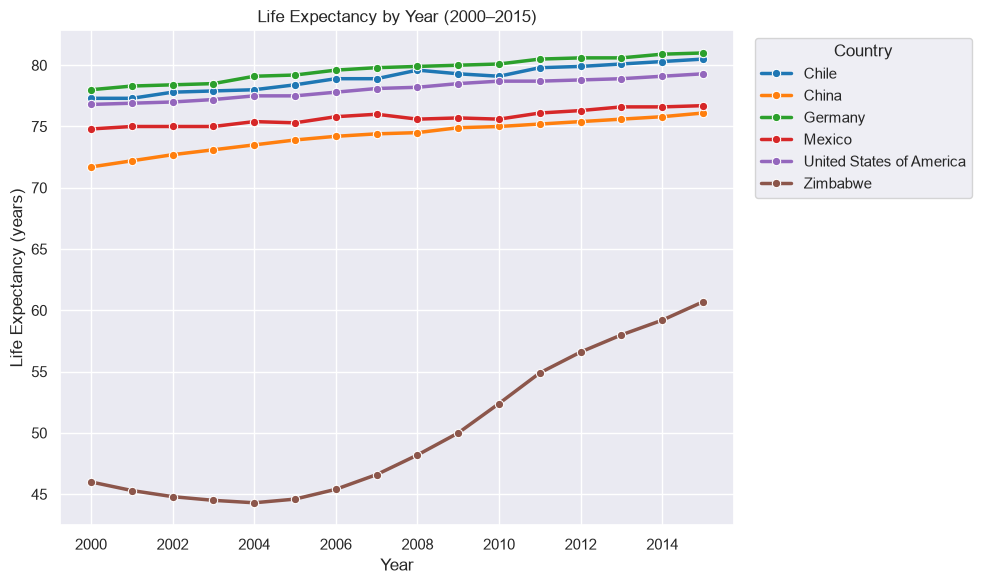

In [83]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure with the specified width and height.
plt.figure(figsize=(10, 6))

# Plot life expectancy over time, using a separate line for each country.
sns.lineplot(
    data=df,
    x="Year",
    y="Life_Expectancy_Years",
    hue="Country",
    palette="tab10",
    linewidth=2.5,
    marker="o"
)

# Add a title and axis labels.
plt.title("Life Expectancy by Year (2000–2015)")
plt.xlabel("Year")
plt.ylabel("Life Expectancy (years)")

# Place the country legend outside the plot on the right.
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit without overlapping.
plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/life_expectancy_trends.png",
    dpi=300,
    bbox_inches="tight"
)
# Render the plot.
plt.show()

Obervations:
- Chile, China, Germany, Mexico, and the United States all exhibit a generally upward trend in life expectancy throughout the period, indicating steady improvements over time.
- Germany, Chile, and the United States show smooth and stable increases with only minor year-to-year fluctuations.
- China demonstrates consistent year-over-year growth, with no noticeable declines or abrupt changes in the trend.
- Mexico follows a gradual upward trajectory, although growth appears to slow slightly during some middle years.
- Zimbabwe displays a distinct pattern, with a slight decline in the early 2000s followed by a sustained and much steeper increase in later years.
- Most countries experience relatively linear growth in life expectancy, suggesting steady long-term improvement rather than sudden changes.

Overall, the chart shows that life expectancy increased across all six countries between 2000 and 2015, though the pace and pattern of growth vary by country.

Pivot table to show break down of data including overall improvement of Life Expectancy for each country.

In [84]:
# Pivot the data so each country has a column for each year.
life_change = df.pivot(
    index="Country",
    columns="Year",
    values="Life_Expectancy_Years"
)

# Add the absolute change in years from 2000 to 2015.
life_change["Change_Years"] = life_change[2015] - life_change[2000]

# Display the pivot table, including the new change column.
display(life_change)


Year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,Change_Years
Country,,,,,,,,,,,,,,,,,
Chile,77.3,77.3,77.8,77.9,78.0,78.4,78.9,78.9,79.6,79.3,79.1,79.8,79.9,80.1,80.3,80.5,3.2
China,71.7,72.2,72.7,73.1,73.5,73.9,74.2,74.4,74.5,74.9,75.0,75.2,75.4,75.6,75.8,76.1,4.4
Germany,78.0,78.3,78.4,78.5,79.1,79.2,79.6,79.8,79.9,80.0,80.1,80.5,80.6,80.6,80.9,81.0,3.0
Mexico,74.8,75.0,75.0,75.0,75.4,75.3,75.8,76.0,75.6,75.7,75.6,76.1,76.3,76.6,76.6,76.7,1.9
United States of America,76.8,76.9,77.0,77.2,77.5,77.5,77.8,78.1,78.2,78.5,78.7,78.7,78.8,78.9,79.1,79.3,2.5
Zimbabwe,46.0,45.3,44.8,44.5,44.3,44.6,45.4,46.6,48.2,50.0,52.4,54.9,56.6,58.0,59.2,60.7,14.7


Observation: Overall, life expectancy improved in all six countries between 2000 and 2015. While most countries experienced relatively modest gains of 2-4 years, Zimbabwe's increase was significantly larger than the others, indicating a markedly different trend over the study period.

#### **b) GDP Trends**
To examine how economic output changed over time, GDP trends are compared across the six countries from 2000 to 2015. A logarithmic scale is used to improve readability because GDP values differ substantially between countries. 

OSError: [Errno 22] Invalid argument: '../figures/gdp_trends.png'

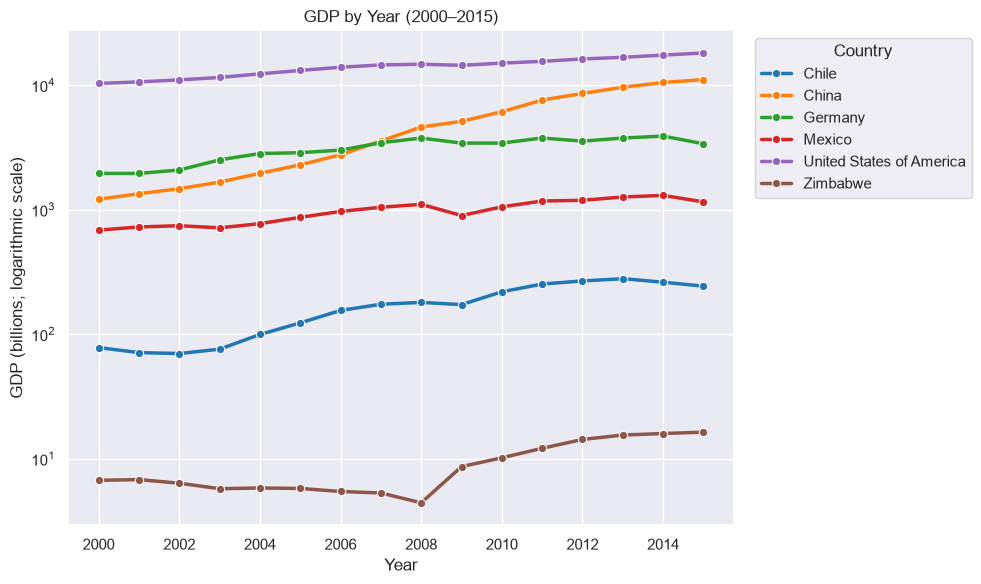

In [85]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot GDP over time, drawing a separate line for each country.
sns.lineplot(
    data=df,
    x="Year",
    y="GDP_Billions",
    hue="Country",
    palette="tab10",
    linewidth=2.5,
    marker="o"
)

# Use a logarithmic y-axis to make differences in GDP easier to compare.
plt.yscale("log")

# Add the chart title and axis labels.
plt.title("GDP by Year (2000–2015)")
plt.xlabel("Year")
plt.ylabel("GDP (billions; logarithmic scale)")

# Place the country legend just outside the plot on the right.
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/gdp_trends.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart.
plt.show()

Observations:
- Chile's GDP increased steadily between 2000 and 2015, with particularly strong growth between 2004 and 2012. Growth slowed slightly after 2013.
- China's GDP showed consistent and substantial growth throughout the study period, with the steepest upward trend among the countries observed and no major periods of decline.
- Germany's GDP generally increased from 2000 to 2015, although growth became more moderate after 2008, with some fluctuations in the later years.
- Mexico's GDP followed an overall upward trend, but experienced a noticeable decline around 2009 before returning to growth in subsequent years.
- The United States' GDP increased steadily over the entire period, with only a minor slowdown around 2008-2009 before continuing its upward trajectory.
- Zimbabwe's GDP declined during the early 2000s and reached its lowest point around 2008. After that, GDP increased steadily through 2015, indicating a period of economic recovery.

Overall Observation
All six countries showed overall GDP growth between 2000 and 2015, although the pace and consistency of growth varied. China, Chile, and the United States exhibited relatively smooth upward trends, while Mexico, Germany, and Zimbabwe experienced more noticeable fluctuations during the period.

#### **c) GDP and Life Expectancy Relationship**
To investigate whether GDP is associated with life expectancy, a scatter plot is used to examine the relationship between the two variables across the six countries. A logarithmic scale is applied to GDP to improve the visibility of patterns among countries with substantially different economic sizes.

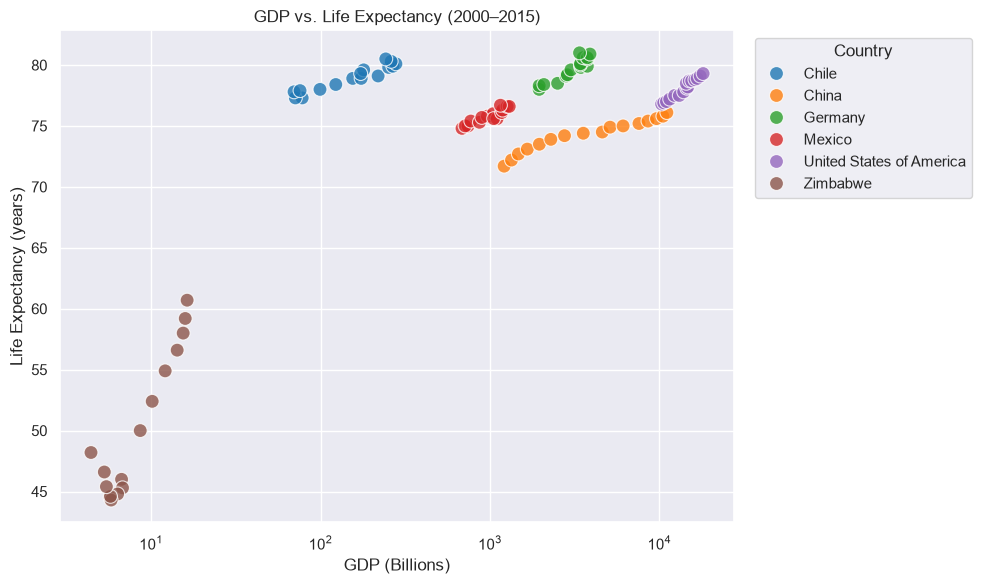

In [86]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot GDP against life expectancy, with a different color for each country.
sns.scatterplot(
    data=df,
    x="GDP_Billions",
    y="Life_Expectancy_Years",
    hue="Country",
    palette="tab10",
    s=100,       # Set the marker size.
    alpha=0.8    # Make markers slightly transparent.
)

# Add a title and labels for both axes.
plt.title("GDP vs. Life Expectancy (2000–2015)")
plt.xlabel("GDP (Billions)")
plt.ylabel("Life Expectancy (years)")

# Place the country legend outside the plot on the right.
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

# Use a logarithmic x-axis to show GDP values across a wide range.
plt.xscale("log")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/gdp_vs_life_expectancy_relationship.png",
    dpi=300,
    bbox_inches="tight"
)
# Display the chart.
plt.show()

Observations
- Chile shows a positive relationship between GDP and life expectancy, with both increasing steadily over time.
- China exhibits strong GDP growth accompanied by a gradual rise in life expectancy.
- Germany demonstrates a consistent upward trend, where higher GDP levels are associated with higher life expectancy.
- Mexico shows modest improvements in life expectancy alongside increasing GDP.
- The United States maintained the highest GDP throughout the period, while life expectancy increased gradually.
- Zimbabwe experienced the largest improvement in life expectancy, particularly during years of economic recovery and GDP growth.

Overall Observation
For all six countries, higher GDP levels generally coincide with higher life expectancy, suggesting a positive association between the two variables. However, the strength of this relationship varies by country, and the chart does not establish causation.

#### **d) GDP Growth and Life Expectancy Improvements**
To examine whether countries with larger GDP increases also experienced greater improvements in life expectancy, percentage GDP growth and absolute life expectancy change are calculated for each country between 2000 and 2015. The resulting values are compared using a scatter plot.

In [ ]:
# Keep only rows for the start and end years used in the comparison.
# Then reshape the data so each country has separate columns for its
# GDP and life expectancy values in 2000 and 2015.
start_end = df[df["Year"].isin([2000, 2015])].pivot(
    index="Country",  # One row per country.
    columns="Year",   # Create year-specific columns.
    values=["GDP_Billions", "Life_Expectancy_Years"]
)

# Build a summary table with one row per country.
change_df = pd.DataFrame({
    # Copy the country names from the pivot table's index.
    "Country": start_end.index,

    # Calculate GDP's percentage change from 2000 to 2015:
    # (ending value - starting value) / starting value * 100.
    "GDP_Percentage_Change": (
        (start_end[("GDP_Billions", 2015)] -
         start_end[("GDP_Billions", 2000)])
        / start_end[("GDP_Billions", 2000)] * 100
    ).values,

    # Calculate the absolute change in life expectancy, measured in years.
    # Positive values indicate an increase; negative values indicate a decrease.
    "Life_Expectancy_Change": (
        start_end[("Life_Expectancy_Years", 2015)] -
        start_end[("Life_Expectancy_Years", 2000)]
    ).values
})

# Sort countries from the smallest GDP percentage change to the largest.
change_df = change_df.sort_values("GDP_Percentage_Change")

# Display the results rounded to two decimal places.
change_df.round(2)

,Country,GDP_Percentage_Change,Life_Expectancy_Change
3,Mexico,68.55,1.9
2,Germany,73.11,3.0
4,United States of America,75.73,2.5
5,Zimbabwe,143.72,14.7
0,Chile,211.48,3.2
1,China,813.42,4.4


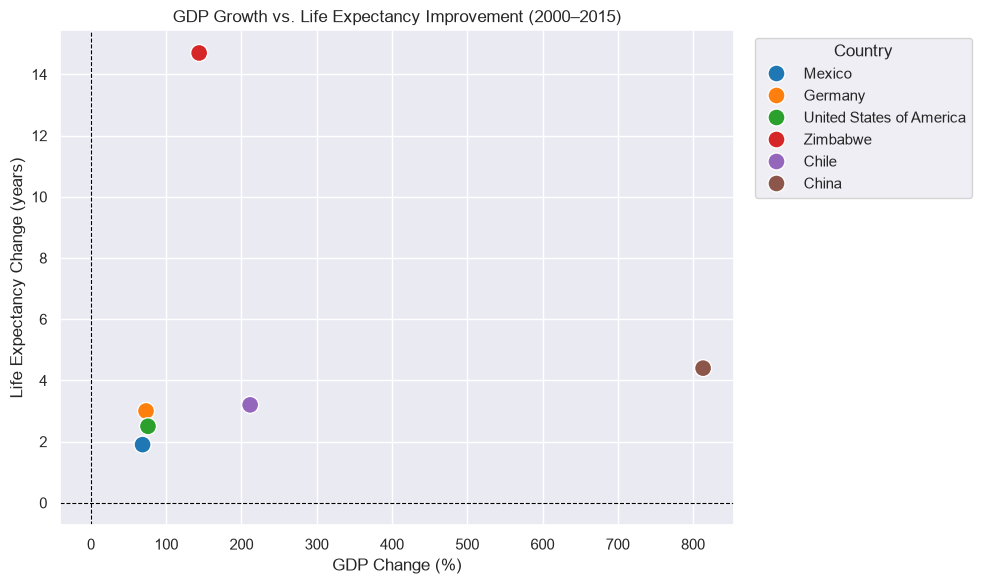

In [ ]:
# Apply a dark grid style to the chart.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot each country's GDP percentage change against its life expectancy change.
sns.scatterplot(
    data=change_df,
    x="GDP_Percentage_Change",
    y="Life_Expectancy_Change",
    hue="Country",  # Use a different color for each country.
    palette="tab10",
    s=150            # Set the marker size.
)

# Add a title and labels to explain the plotted variables.
plt.title("GDP Growth vs. Life Expectancy Improvement (2000–2015)")
plt.xlabel("GDP Change (%)")
plt.ylabel("Life Expectancy Change (years)")

# Add dashed reference lines at zero to distinguish increases from decreases.
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")

# Place the country legend outside the plot on the right.
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/gdp_growth_vs_life_expectancy_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart.
plt.show()

Observations
- Mexico recorded the smallest gains, with GDP increasing by 68.6% and life expectancy improving by only 1.9 years.
- Germany experienced moderate GDP growth (73.1%) alongside a 3.0-year increase in life expectancy.
- The United States saw GDP grow by 75.7%, while life expectancy increased by 2.5 years.
- Zimbabwe achieved the largest improvement in life expectancy (+14.7 years), despite GDP growth (143.7%) being much lower than China's.
- Chile more than tripled its GDP (211.5% increase), but life expectancy rose by a relatively modest 3.2 years.
- China recorded the largest GDP growth (813.4%), yet its life expectancy increased by 4.4 years, which was smaller than Zimbabwe's improvement.

Overall Observation \
Countries with larger GDP increases did not necessarily experience the largest improvements in life expectancy. For example, China had the greatest GDP growth, while Zimbabwe experienced the greatest life expectancy gain. This suggests that GDP growth alone does not fully explain changes in life expectancy.

## **5. Key Findings**

### 1. Life expectancy increased across all six countries
Between 2000 and 2015, life expectancy increased in Chile, China, Germany, Mexico, the United States of America, and Zimbabwe. However, the magnitude of improvement varied considerably.
Zimbabwe experienced the largest increase, from 46.0 to 60.7 years, a gain of **14.7 years**. In comparison, the other five countries recorded improvements ranging from 1.9 to 4.4 years.

### 2. Zimbabwe experienced the largest improvement in life expectancy
Zimbabwe's life expectancy declined during the early part of the study period before increasing substantially in subsequent years. Its overall improvement was considerably larger than that of the other countries.
Mexico recorded the smallest improvement, at **1.9 years**, increasing from 74.8 years in 2000 to 76.7 years in 2015.

### 3. GDP generally increased, but the growth patterns differed
GDP increased overall between 2000 and 2015 in all six countries, although the rate and consistency of growth varied.
China recorded the largest percentage increase in GDP among the six countries, at approximately **813.4%**. Chile also experienced substantial growth, at approximately **211.5%**. The other countries recorded smaller percentage increases over the same period.
The GDP time-series chart also shows periods of fluctuation rather than uninterrupted growth in every country.

### 4. GDP and life expectancy generally showed a positive association
The scatter plot suggests that higher GDP values generally coincided with higher life expectancy within the observed country-level data. However, the pattern and magnitude of change differed across countries.
The United States had the highest GDP values in the dataset, while Zimbabwe started with the lowest life expectancy and subsequently recorded the largest improvement.
These observations suggest an association between GDP and life expectancy, but they do not establish that increases in GDP directly caused increases in life expectancy.

### 5. Larger GDP increases did not necessarily correspond to larger life expectancy gains
Comparing percentage GDP change with absolute life expectancy improvement revealed that the country with the largest GDP increase was not the country with the largest life expectancy gain.
China recorded an approximately 813.4% increase in GDP and a 4.4-year increase in life expectancy. Zimbabwe, in contrast, recorded a 143.7% increase in GDP and a 14.7-year increase in life expectancy.
This comparison indicates that GDP growth alone does not explain the differences in life expectancy improvements observed across these six countries.

## **6. Limitations**

### 1. Limited country coverage
The dataset contains only six countries. These countries provide a useful basis for comparing different trends, but they do not represent all countries or the full range of economic and public-health conditions worldwide. Therefore, the findings should not be generalized to all countries.

### 2. Limited observation period
The analysis covers 2000–2015. The findings describe patterns within this period and do not establish whether similar trends continued after 2015.

### 3. GDP is an incomplete measure of economic conditions
The analysis uses total GDP rather than GDP per capita or a direct measure of household living standards. Total GDP can increase because of population growth as well as changes in economic output per person. It therefore does not fully represent individual prosperity or access to healthcare and other essential services.
The original dataset's documentation should also be consulted to establish the GDP currency, price basis, and whether the figures are adjusted for inflation. These details affect how GDP changes should be interpreted.

### 4. Association does not establish causation
The analysis identifies patterns between GDP and life expectancy but does not test whether GDP changes caused changes in life expectancy. Other factors, such as healthcare access, education, nutrition, sanitation, public-health interventions, and demographic changes, may also influence life expectancy.
These factors were not included in the current analysis.

### 5. Exploratory analysis only
The project uses descriptive analysis and visualizations. It does not include formal statistical inference, controls for other explanatory variables, or a predictive model. The results identify patterns worth investigating further, but they do not establish statistical significance or support causal conclusions.

## **7. Conclusion**

This project explored GDP and life expectancy trends across Chile, China, Germany, Mexico, the United States of America, and Zimbabwe from 2000 to 2015 using Python, pandas, Matplotlib, and Seaborn.

The analysis found that life expectancy increased in all six countries, although the magnitude of improvement varied substantially. Zimbabwe recorded the largest increase, at 14.7 years, while Mexico recorded the smallest, at 1.9 years. GDP also increased overall across the six countries, but the scale and consistency of growth differed.

Although GDP and life expectancy generally showed a positive association in the observed data, the comparison of changes between 2000 and 2015 demonstrated that larger GDP increases did not necessarily correspond to larger improvements in life expectancy. China's substantial GDP increase, for example, was accompanied by a smaller life expectancy gain than Zimbabwe's.

The results suggest that GDP alone is insufficient to explain the differences in life expectancy improvements observed in this dataset. However, this exploratory analysis cannot determine which other factors contributed to those differences or establish a causal relationship between GDP and life expectancy.

Overall, the project demonstrates a reproducible Python workflow for inspecting and preparing data, analyzing trends, comparing changes over time, visualizing relationships, and communicating findings with appropriate consideration of analytical limitations. Further work could incorporate GDP per capita, healthcare and demographic indicators, and a broader set of countries to investigate these relationships in greater depth.